# 03 · Signatures — embryonic module geography (Nam et al. 2019)

Score Gast/pSom/Crest on the rooted manifold and read the **Gate 2** geography from the raw
per-cell scores (deliverable panels show RAW scores; smoothing aids analysis only). This is the
**non-branching** case: Gast and pSom overlap at the root pole and Crest rises as an inverse
terminal gradient. Gate 2 = GO; Gate 3 = NA (no bifurcation). Deliverables:
`{Gast,pSom,Crest}_signature.pdf` + colorbars, `signatures.h5ad`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
from scipy.stats import spearmanr

In [1]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold and confirm module gene recovery

In [1]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 22605 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 69/81 genes present
pSom: 79/98 genes present
Crest: 92/104 genes present


### Gate 2 — module geography and the Crest-arm flag
Global module means give the Linear-split class; smoothed correlations give the axis structure;
pseudotime gradients confirm the terminal ordering. The **flag** check: Crest enriches the Gast
end only if `Crest_sm–Gast_sm` is positive while `Crest_sm–pSom_sm` is negative. Here Crest
opposes *both* Gast and pSom, so there is no inversion — Crest is a clean inverse terminal
gradient.

In [1]:
print('global module means (Linear split metric):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
rGp = np.corrcoef(adata.obs['Gast_sm'], adata.obs['pSom_sm'])[0,1]
rCG = np.corrcoef(adata.obs['Crest_sm'], adata.obs['Gast_sm'])[0,1]
rCp = np.corrcoef(adata.obs['Crest_sm'], adata.obs['pSom_sm'])[0,1]
print('smoothed spatial correlations (geography):')
print(f'  Gast_sm vs pSom_sm: r = {rGp:+.2f}')
print(f'  Crest_sm vs Gast_sm: r = {rCG:+.2f}')
print(f'  Crest_sm vs pSom_sm: r = {rCp:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
flag = (rCG > 0) and (rCp < 0)
print(f'Crest-enriches-Gast-arm flag: {flag} (Crest opposes both Gast and pSom -> no inversion)')
print('Gate 2: Gast/pSom overlap at root pole + inverse terminal Crest -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

global module means (Linear split metric): {'Gast': -0.0363, 'pSom': 0.0078, 'Crest': 0.0087}
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.23
  Crest_sm vs Gast_sm: r = -0.73
  Crest_sm vs pSom_sm: r = -0.71
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.625
  pSom_sm: rho = -0.659
  Crest_sm: rho = +0.709
Neural-crest-high decile mean pseudotime = 0.86 (terminal if ~1)
Crest-enriches-Gast-arm flag: False (Crest opposes both Gast and pSom -> no inversion)
Gate 2: Gast/pSom overlap at root pole + inverse terminal Crest -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Signature maps (whole panel, house linear layout)
Raw per-cell scores in the house linear layout (root at left), one quick 3-panel view before
the individual deliverable panels.

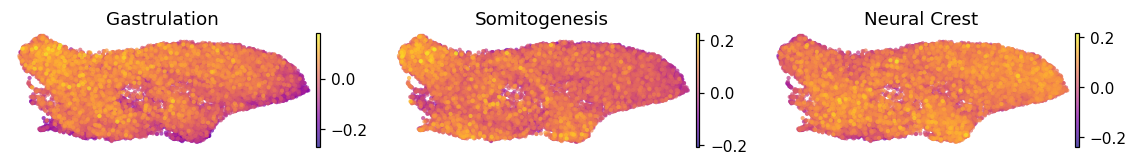

In [1]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout()

### Deliverable panels + colorbars (RAW per-cell scores)
One `(3.5,1.5)` panel per module in the shared linear orientation, plus an external colorbar
each, matching the reference deliverable format.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


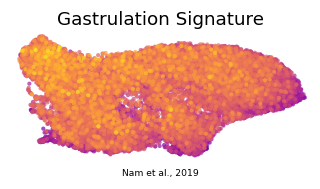

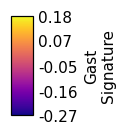

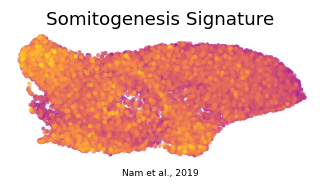

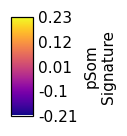

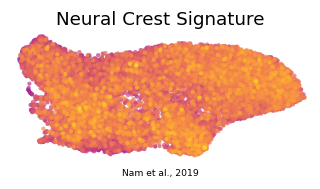

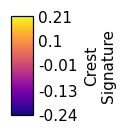

In [1]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Nam et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [1]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (22605, 19650)
